In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../Dataset/housing.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (20640, 10)


In [3]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [4]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Data Types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate Rows:
0


In [5]:
median_bedrooms = df["total_bedrooms"].median()

df["total_bedrooms"] = df["total_bedrooms"].fillna(median_bedrooms)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [6]:
print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


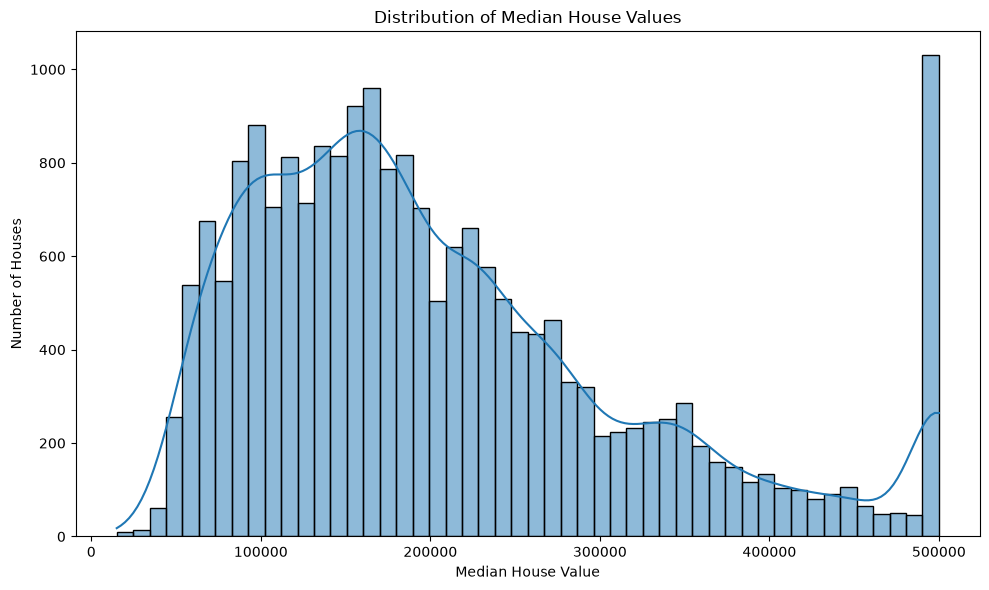

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(df["median_house_value"], bins=50, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Number of Houses")
plt.tight_layout()

plt.savefig("../Visualization/house_price_distribution.png")
plt.show()

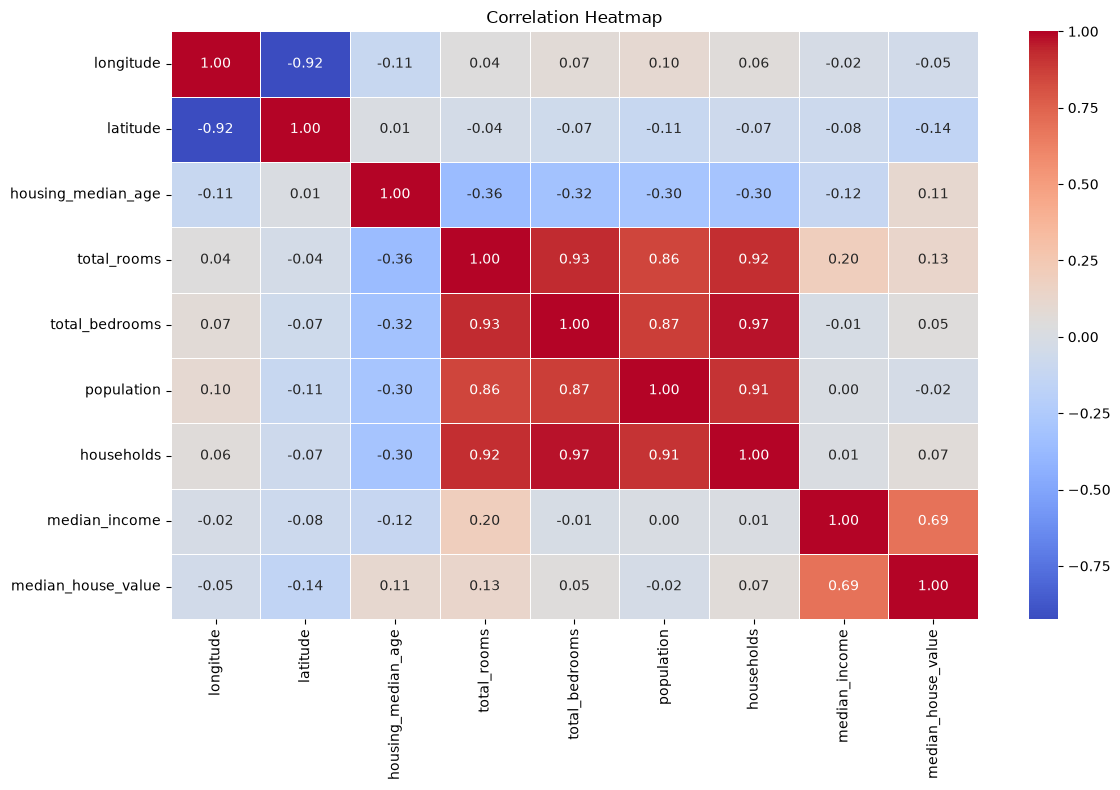

In [8]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../Visualization/correlation_heatmap.png")
plt.show()

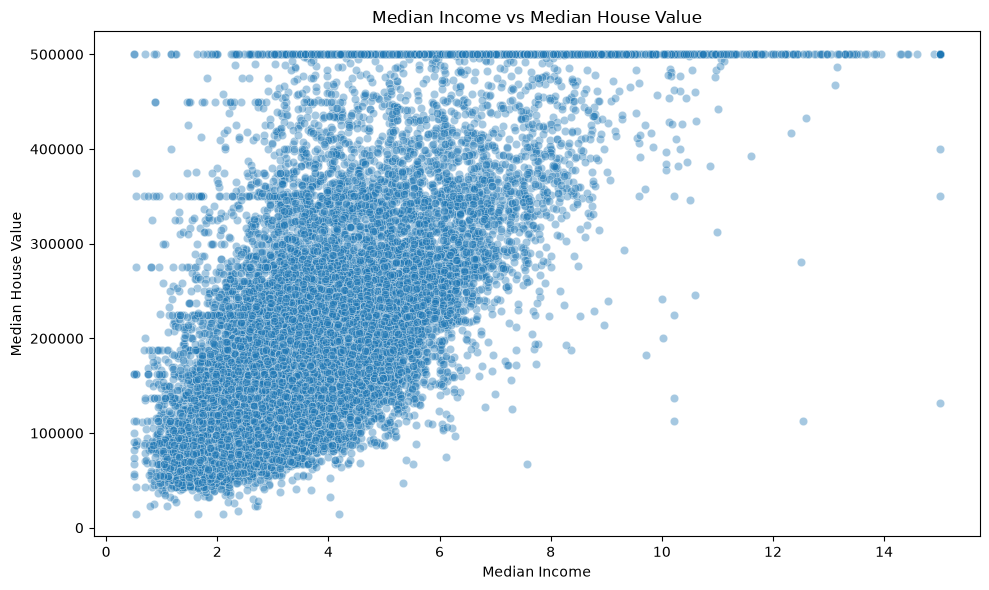

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.4
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout()

plt.savefig("../Visualization/income_vs_house_value.png")
plt.show()

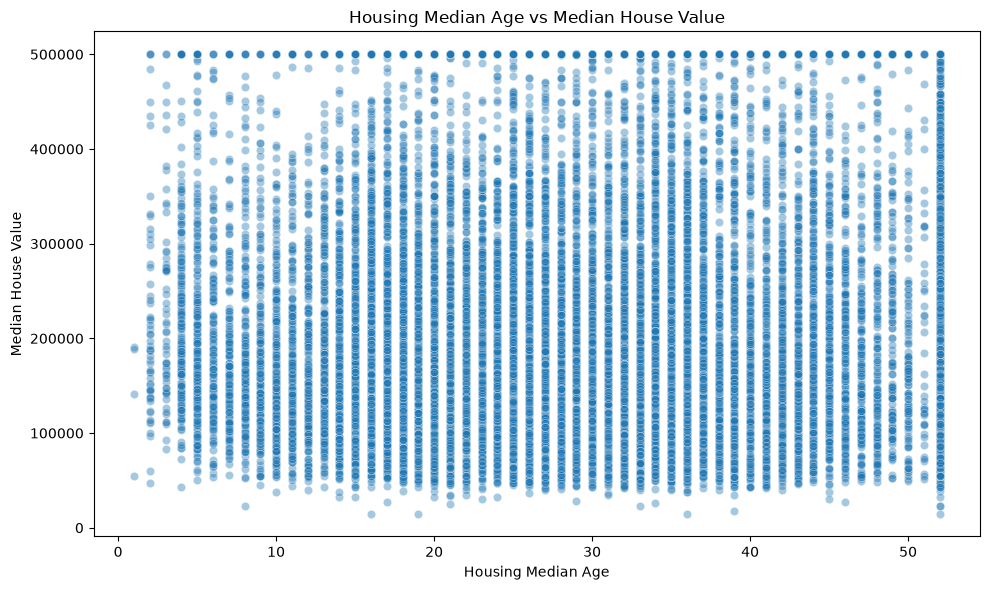

In [10]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="housing_median_age",
    y="median_house_value",
    alpha=0.4
)

plt.title("Housing Median Age vs Median House Value")
plt.xlabel("Housing Median Age")
plt.ylabel("Median House Value")
plt.tight_layout()

plt.savefig("../Visualization/age_vs_house_value.png")
plt.show()

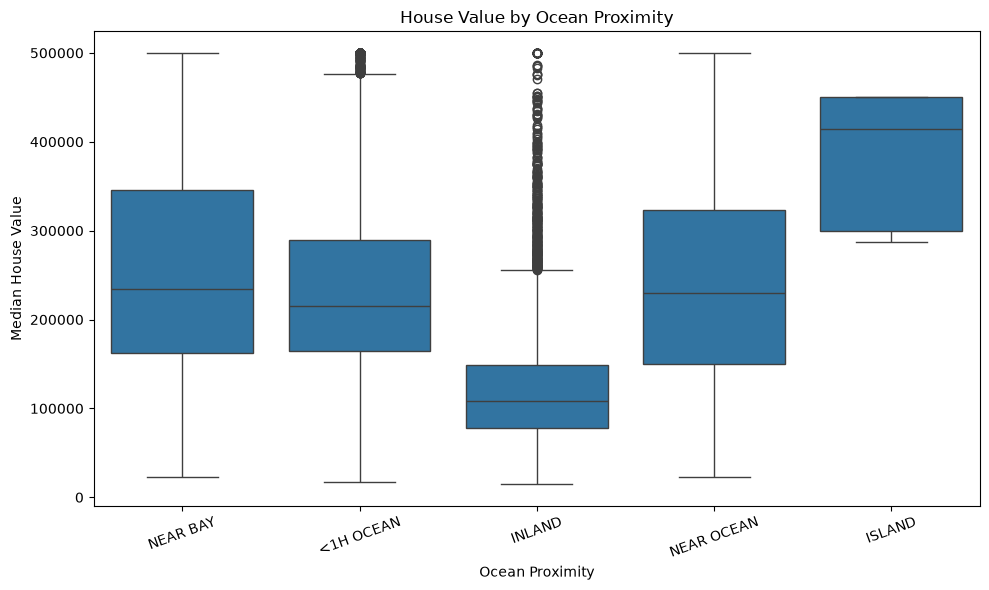

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value"
)

plt.title("House Value by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("../Visualization/house_value_by_ocean_proximity.png")
plt.show()

In [12]:
print("Ocean Proximity Categories:")
print(df["ocean_proximity"].value_counts())

Ocean Proximity Categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [13]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (20640, 9)
Target shape: (20640,)

Feature columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numerical_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

categorical_features = [
    "ocean_proximity"
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 8
Categorical features: 1


In [16]:
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [18]:
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [19]:
y_pred = linear_model.predict(X_test)

print("Predictions generated successfully!")
print("\nFirst 10 actual prices:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

Predictions generated successfully!

First 10 actual prices:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 predicted prices:
[ 54055.44889898 124225.33893718 255489.37949166 268002.43156919
 262769.43481568 139606.3039556  290665.42391417 228264.87637529
 256506.78561005 407923.85843486]


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Performance")
print("-----------------------------------")
print(f"MAE  : ${mae:,.2f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Model Performance
-----------------------------------
MAE  : $50,670.74
RMSE : $70,060.52
R²   : 0.6254


In [21]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [22]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [23]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions generated successfully!")

print("\nFirst 10 actual prices:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Random Forest predicted prices:")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!

First 10 actual prices:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 Random Forest predicted prices:
[ 51744.    71115.   461540.37 255273.   268425.   162987.   226880.02
 168563.   288998.05 484745.72]


In [24]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Model Performance")
print("--------------------------------")
print(f"MAE  : ${mae_rf:,.2f}")
print(f"RMSE : ${rmse_rf:,.2f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Model Performance
--------------------------------
MAE  : $31,628.59
RMSE : $48,941.95
R²   : 0.8172


,Model,MAE,RMSE,R2 Score
0,Linear Regression,50670.738241,70060.521845,0.625424
1,Random Forest,31628.592391,48941.954703,0.817209


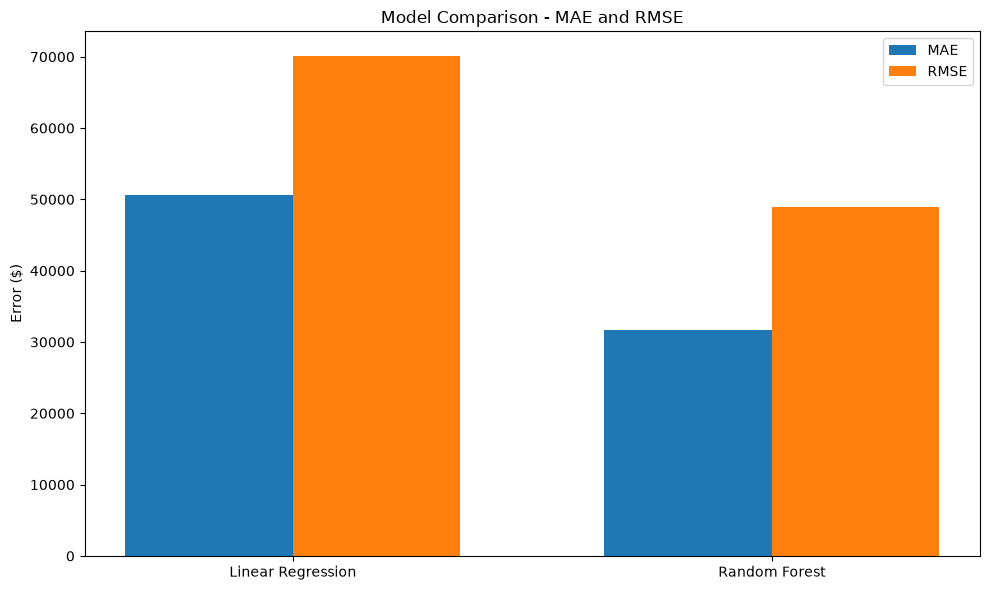

In [25]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, mae_rf],
    "RMSE": [rmse, rmse_rf],
    "R2 Score": [r2, r2_rf]
})

display(model_comparison)

plt.figure(figsize=(10, 6))

x = np.arange(len(model_comparison))
width = 0.35

plt.bar(x - width/2, model_comparison["MAE"], width, label="MAE")
plt.bar(x + width/2, model_comparison["RMSE"], width, label="RMSE")

plt.xticks(x, model_comparison["Model"])
plt.ylabel("Error ($)")
plt.title("Model Comparison - MAE and RMSE")
plt.legend()
plt.tight_layout()

plt.savefig("../Visualization/model_comparison.png")
plt.show()

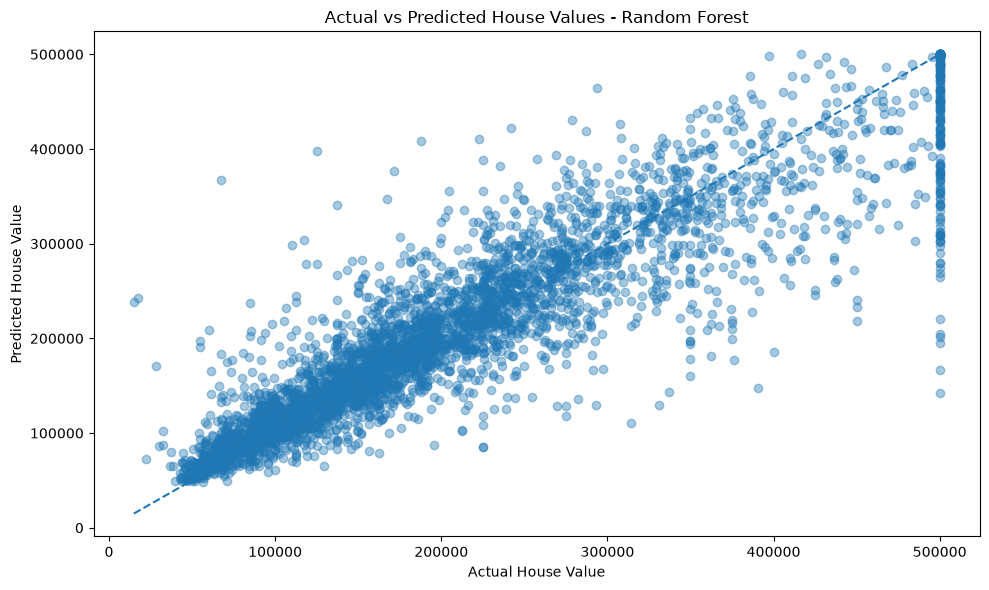

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.4)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted House Values - Random Forest")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.tight_layout()

plt.savefig("../Visualization/actual_vs_predicted.png")
plt.show()

In [27]:
# Get feature names after preprocessing
feature_names = random_forest_model.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest feature importances
importances = random_forest_model.named_steps["regressor"].feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

Top 10 Important Features:


,Feature,Importance
7,num__median_income,0.490642
9,cat__ocean_proximity_INLAND,0.140925
0,num__longitude,0.105889
1,num__latitude,0.101597
2,num__housing_median_age,0.051935
5,num__population,0.032573
4,num__total_bedrooms,0.023819
3,num__total_rooms,0.023366
6,num__households,0.018367
12,cat__ocean_proximity_NEAR OCEAN,0.006336


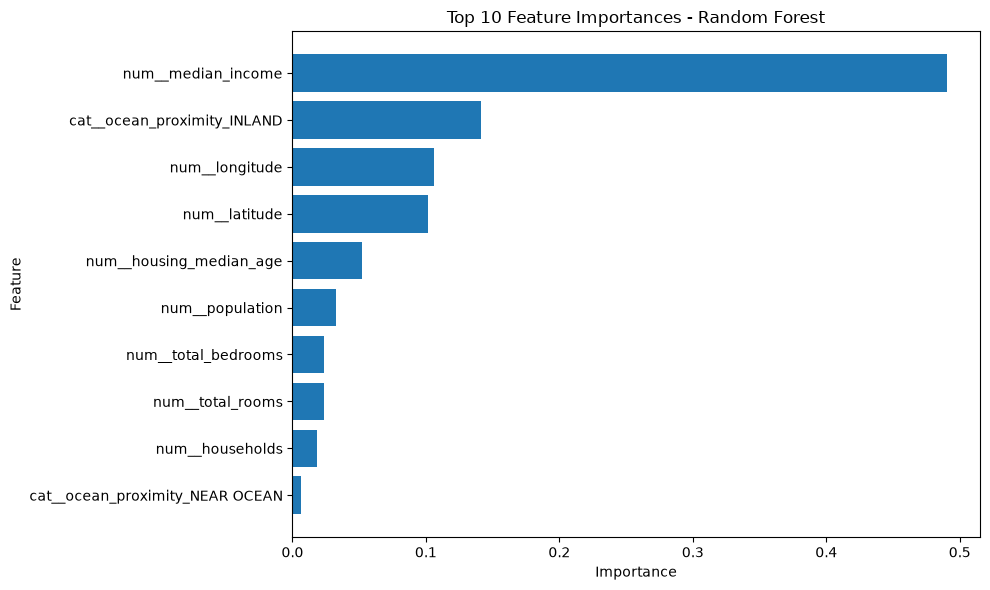

In [28]:
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig("../Visualization/feature_importance.png")
plt.show()

In [29]:
final_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, mae_rf],
    "RMSE": [rmse, rmse_rf],
    "R2 Score": [r2, r2_rf]
})

print("Final Model Results:")
display(final_results)

Final Model Results:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,50670.738241,70060.521845,0.625424
1,Random Forest,31628.592391,48941.954703,0.817209


In [30]:
prediction_results = pd.DataFrame({
    "Actual_House_Value": y_test.values,
    "Predicted_House_Value": y_pred_rf
})

prediction_results["Absolute_Error"] = (
    abs(
        prediction_results["Actual_House_Value"]
        - prediction_results["Predicted_House_Value"]
    )
)

prediction_results.to_csv(
    "../Dataset/house_price_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")
print("Rows saved:", len(prediction_results))

display(prediction_results.head(10))

Prediction results saved successfully!
Rows saved: 4128


,Actual_House_Value,Predicted_House_Value,Absolute_Error
0,47700.0,51744.00,4044.00
1,45800.0,71115.00,25315.00
2,500001.0,461540.37,38460.63
3,218600.0,255273.00,36673.00
4,278000.0,268425.00,9575.00
5,158700.0,162987.00,4287.00
6,198200.0,226880.02,28680.02
7,157500.0,168563.00,11063.00
8,340000.0,288998.05,51001.95
9,446600.0,484745.72,38145.72
